# Detailed evaluation — reader ← GNN

Reads `evaluated_result_detailed.csv`, written by `src/evaluation/evaluate_detailed.py`.
Every metric is described in `docs/detailed_evaluation.md`. The last section compares this arm
paper by paper with another arm's detailed CSV, if one exists.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

ARM = 'reader ← GNN'
df = pd.read_csv('evaluated_result_detailed.csv')

NUMERIC = ['rouge1_f', 'rouge2_f', 'rougeL_f', 'bertscore_p', 'bertscore_r', 'bertscore_f1',
           'llm_coherence', 'llm_language',
           'field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
           'subfield', 'problem', 'task',
           'claims_total', 'claims_supported', 'claims_contradicted', 'claim_precision',
           'id_rank', 'id_correct', 'pair_score',
           'tfidf_rank', 'ontarget_gold_sim', 'ontarget_max_ref_sim', 'ontarget_margin']
NUMERIC = [c for c in NUMERIC if c in df.columns]   # pair_score only exists with --against
for col in NUMERIC:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['tfidf_top1'] = (df['tfidf_rank'] == 1).astype(float)

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows')
df.head(3)

945 rows


,node_id,mag_id,original_abstract,generated_abstract,num_of_neighbors,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,...,claims_supported,claims_contradicted,claim_precision,llm_coherence,llm_language,id_rank,id_correct,id_options,tfidf_top1,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,This paper introduces a novel optimization fra...,69,0.2769,0.0124,0.1415,0.8460,0.8183,...,0,6,0.00,6,8,1,1.0,160912|88972|1564|5100,0.0,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,This paper introduces a novel deep learning fr...,50,0.2771,0.0506,0.1360,0.8494,0.8269,...,2,5,0.25,6,7,5,0.0,145426|169088|127541|39733,0.0,46-50
2,1121,2964693852,Various formal languages have been proposed in...,This paper introduces a novel framework for mo...,37,0.2893,0.0500,0.1488,0.8383,0.8597,...,2,6,0.20,6,8,2,0.0,152273|184353|213866|202507,1.0,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

def dist_plot(col: str, values: list, title: str, xlabel: str, color: str):
    """Count of papers per score value."""
    counts = df[col].dropna().round().astype(int).value_counts().reindex(values, fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.bar([str(v) for v in values], counts.values, color=color, edgecolor='white', linewidth=0.6)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                str(int(v)), ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Number of abstracts')
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()
    return counts

## Summary: every metric

In [3]:
summary = pd.DataFrame({
    'mean': df[NUMERIC + ['tfidf_top1']].mean(),
    'median': df[NUMERIC + ['tfidf_top1']].median(),
    'n': df[NUMERIC + ['tfidf_top1']].notna().sum(),
}).round(3)
summary

,mean,median,n
rouge1_f,0.336,0.335,945
rouge2_f,0.054,0.050,945
rougeL_f,0.158,0.156,945
bertscore_p,0.848,0.848,945
bertscore_r,0.843,0.844,945
bertscore_f1,0.846,0.846,945
llm_coherence,6.254,6.000,945
llm_language,7.596,8.000,945
field_match,0.789,1.000,941
contribution_match,0.699,1.000,945


## Kept from the current evaluator

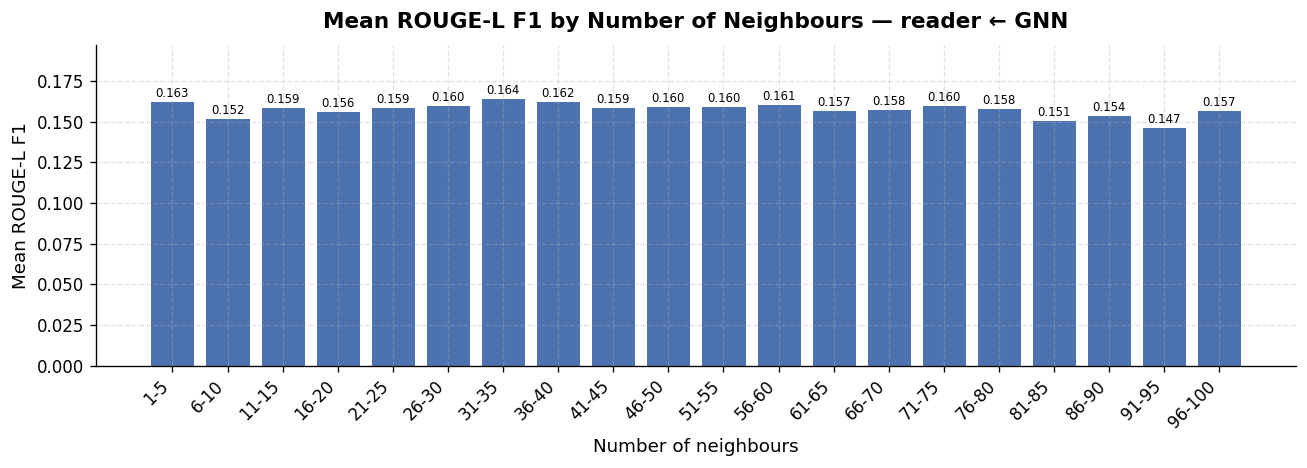

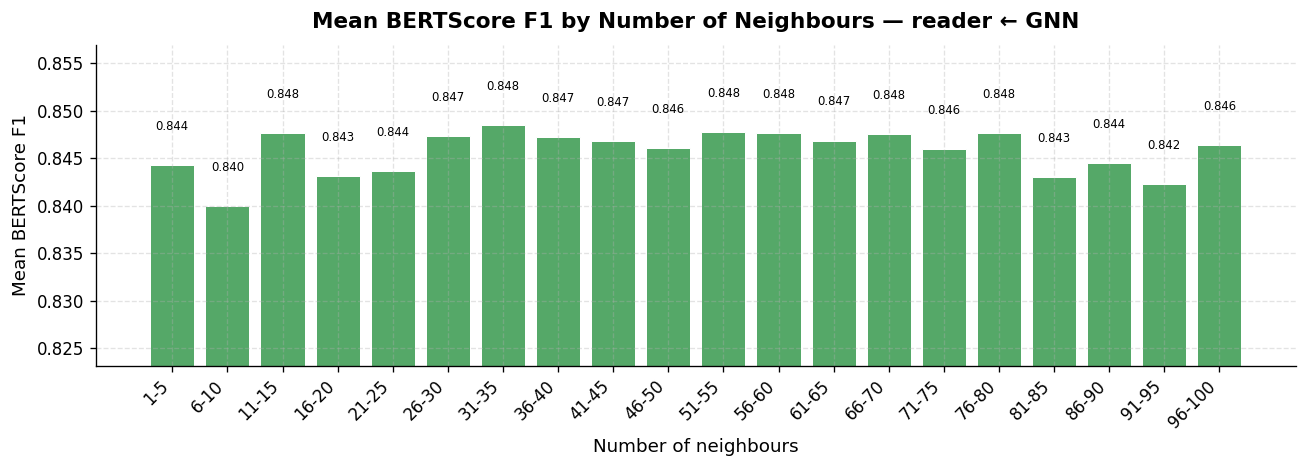

In [4]:
# ── ROUGE-L and BERTScore by neighbours ──────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean, title=f'Mean ROUGE-L F1 by Number of Neighbours — {ARM}',
         ylabel='Mean ROUGE-L F1', color='#4C72B0', ylim=(0, max(rougel_mean.dropna()) * 1.2))

bert_mean = weighted_group_mean(df, 'bertscore_f1')
bar_plot(bert_mean, title=f'Mean BERTScore F1 by Number of Neighbours — {ARM}',
         ylabel='Mean BERTScore F1', color='#55A868',
         ylim=(bert_mean.dropna().min() * 0.98, bert_mean.dropna().max() * 1.01))

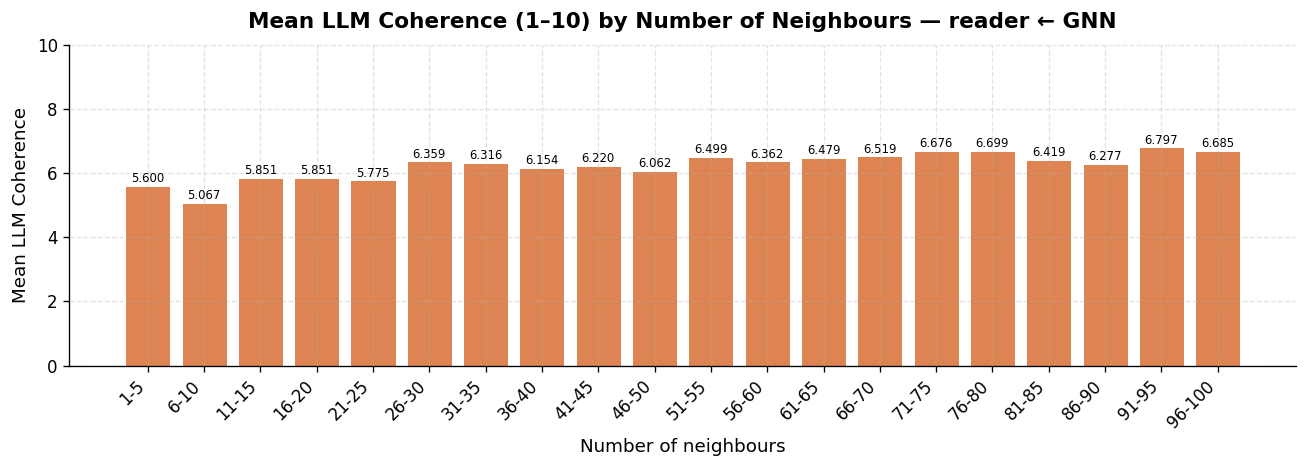

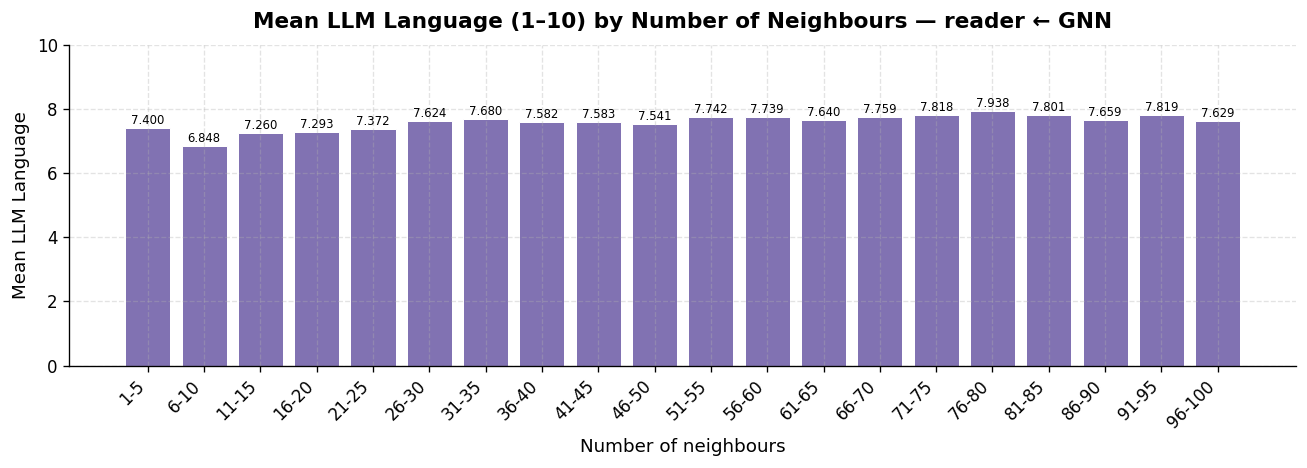

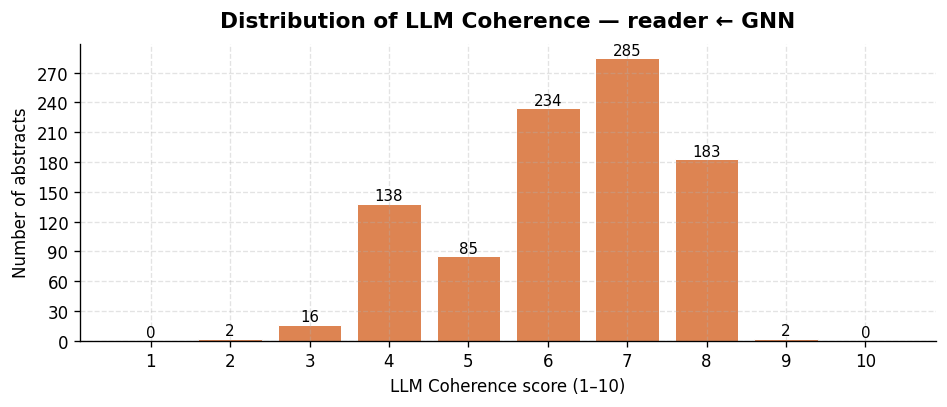

llm_coherence
1       0
2       2
3      16
4     138
5      85
6     234
7     285
8     183
9       2
10      0
Name: count, dtype: int64

In [5]:
# ── Coherence and language ───────────────────────────────────────────────────
bar_plot(weighted_group_mean(df, 'llm_coherence'),
         title=f'Mean LLM Coherence (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Coherence', color='#DD8452', ylim=(0, 10))
bar_plot(weighted_group_mean(df, 'llm_language'),
         title=f'Mean LLM Language (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Language', color='#8172B2', ylim=(0, 10))
dist_plot('llm_coherence', list(range(1, 11)), f'Distribution of LLM Coherence — {ARM}',
          'LLM Coherence score (1–10)', '#DD8452')

## A. Blind facets

Each abstract is labelled on its own from fixed lists; the score is whether the generated
label matches the gold label. Field is expected near the ceiling for every arm.

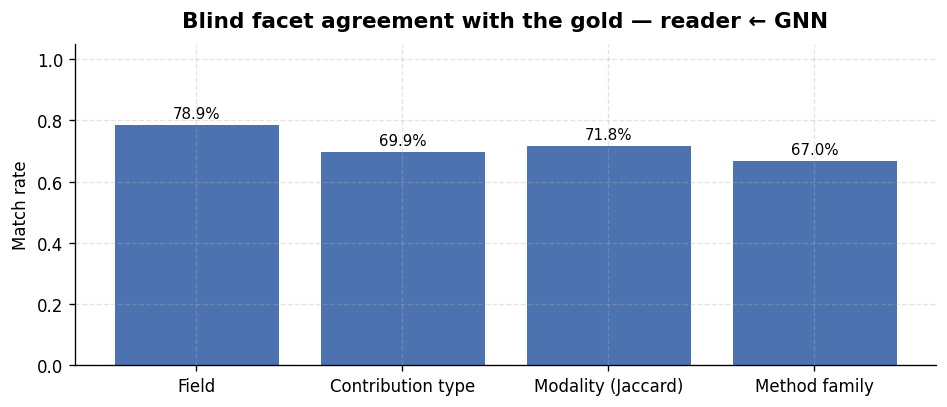

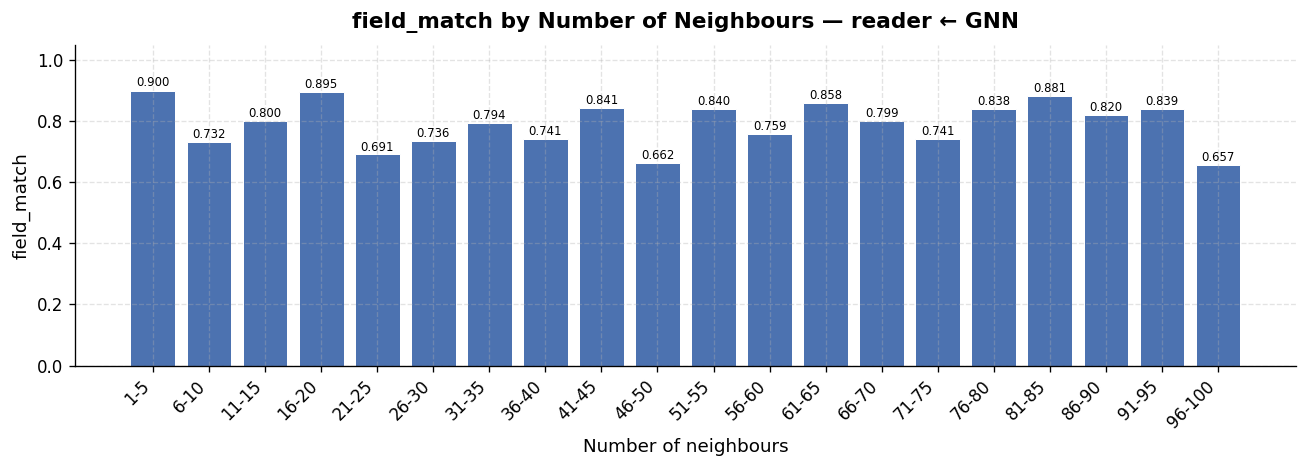

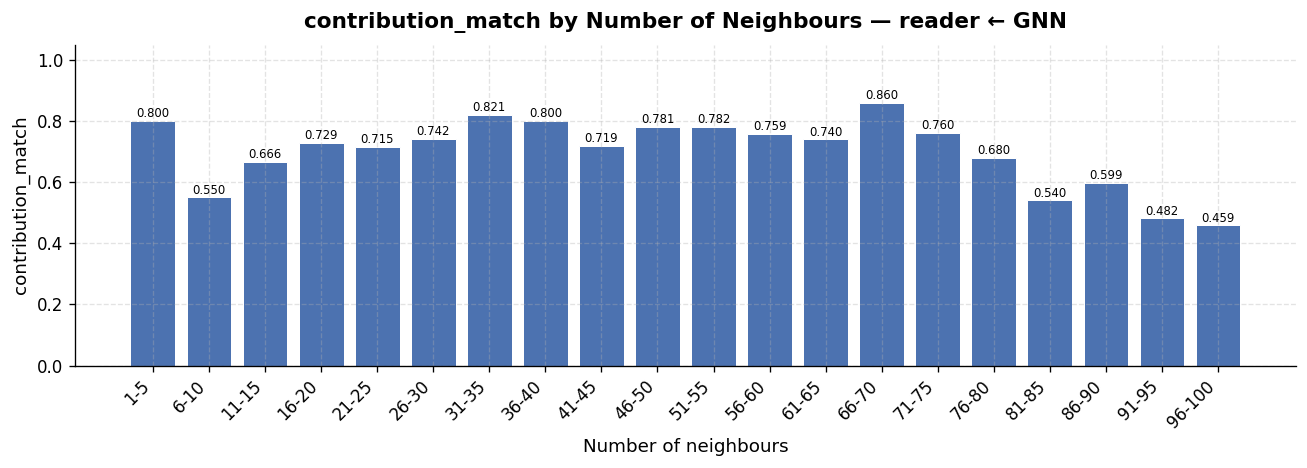

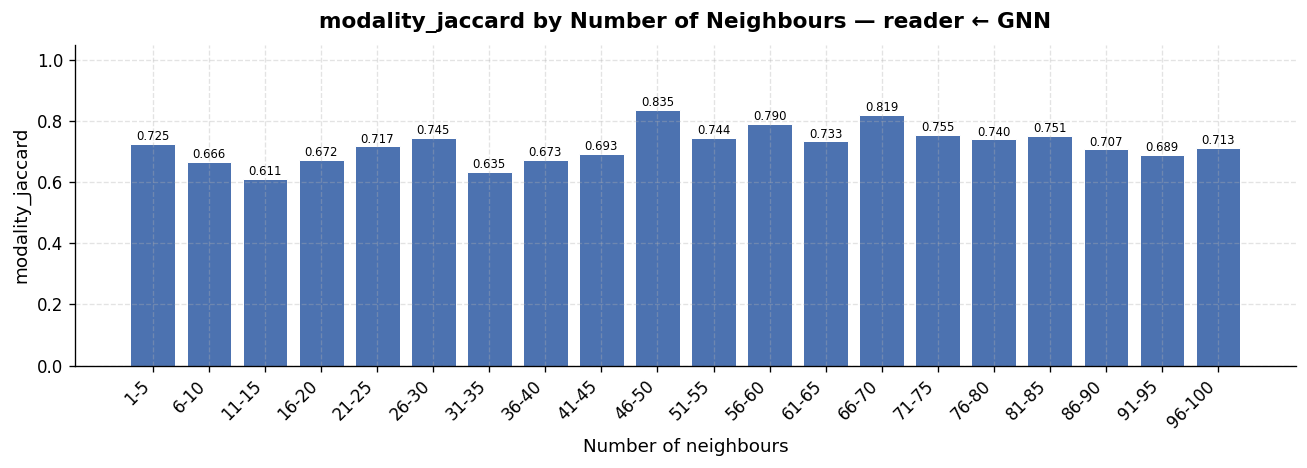

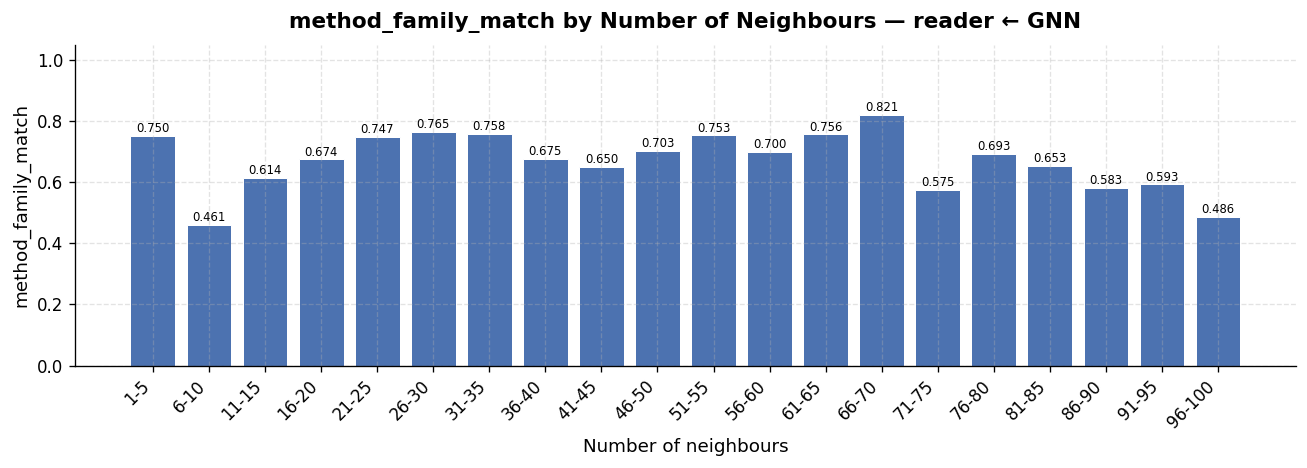

In [6]:
FACETS = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match']
FACET_LABELS = ['Field', 'Contribution type', 'Modality (Jaccard)', 'Method family']
rates = df[FACETS].mean().values

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(FACET_LABELS, rates, color='#4C72B0', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Match rate')
ax.set_title(f'Blind facet agreement with the gold — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

for col in FACETS:
    bar_plot(weighted_group_mean(df, col), title=f'{col} by Number of Neighbours — {ARM}',
             ylabel=col, color='#4C72B0', ylim=(0, 1.05))

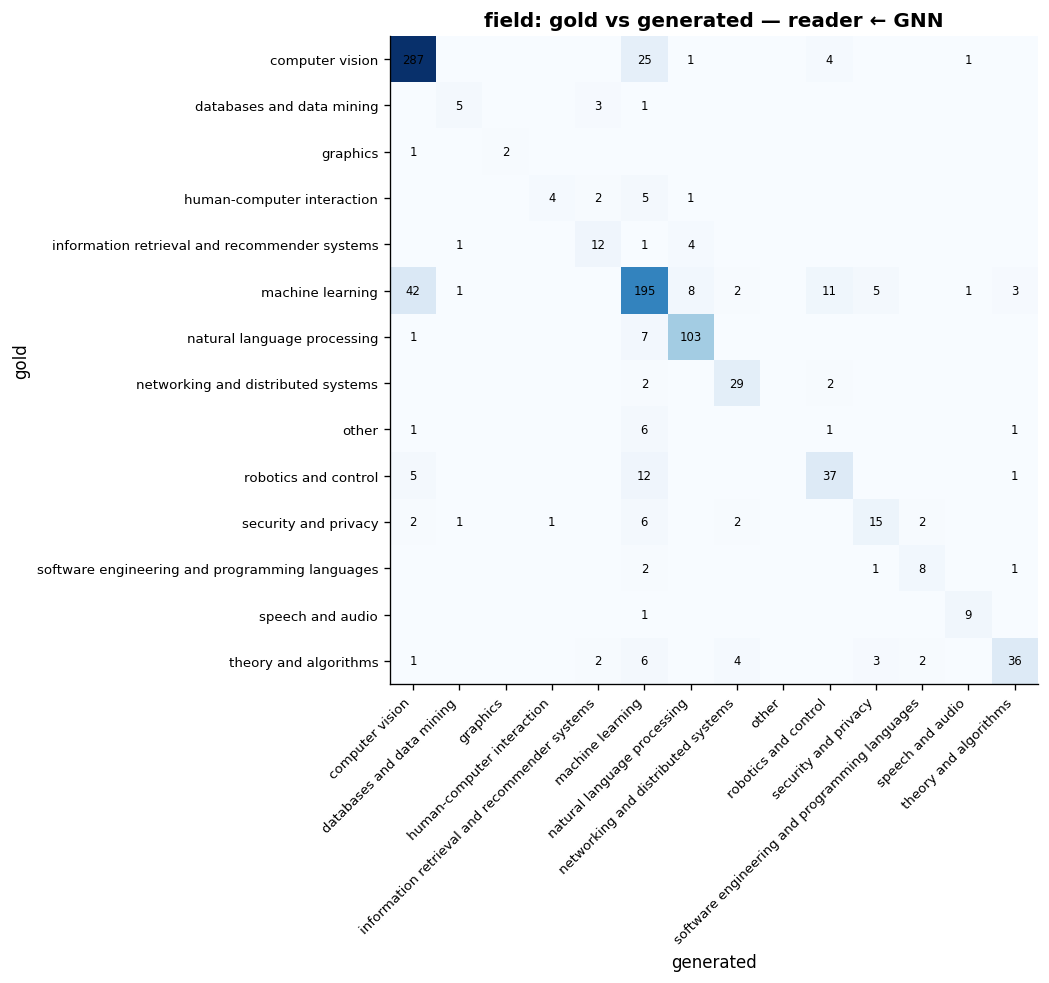

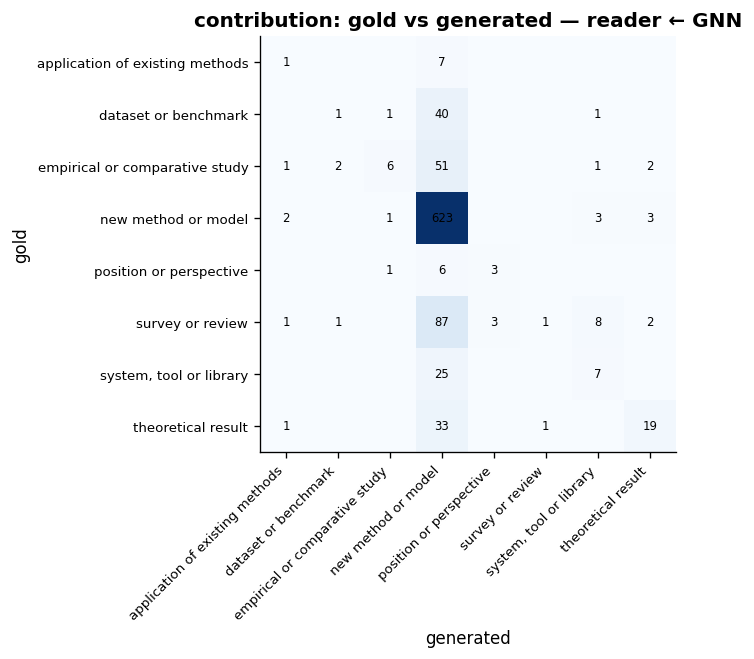

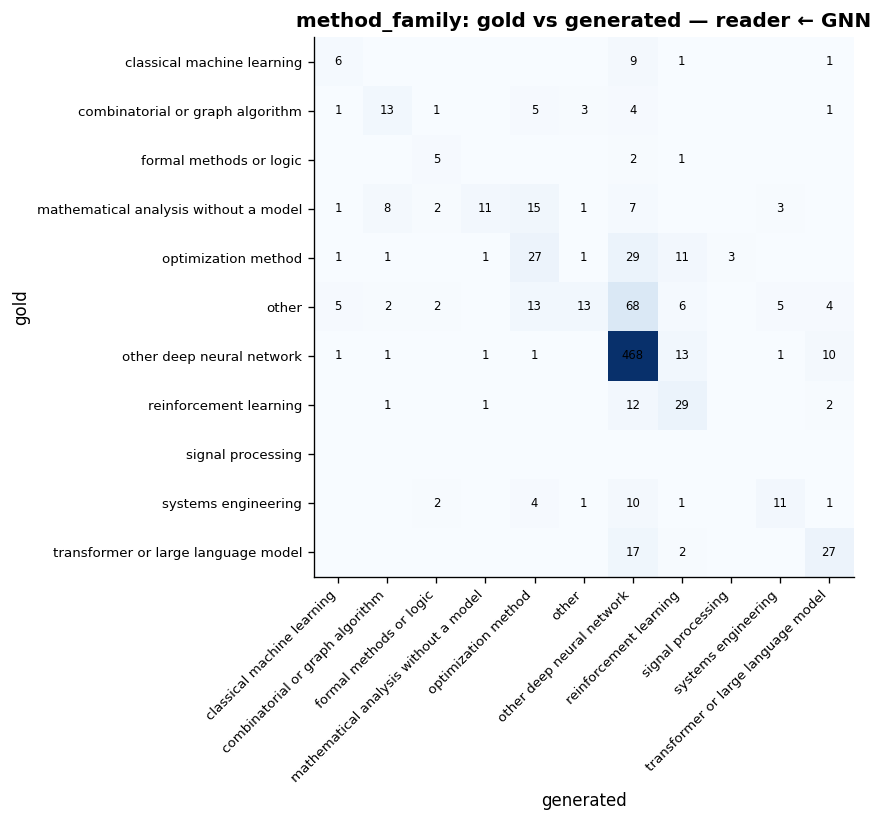

In [7]:
# ── Confusion tables: gold label (rows) vs generated label (columns) ─────────
def confusion(facet: str):
    table = pd.crosstab(df[f'gold_{facet}'], df[f'gen_{facet}'])
    labels = sorted(set(table.index) | set(table.columns))
    table = table.reindex(index=labels, columns=labels, fill_value=0)
    fig, ax = plt.subplots(figsize=(0.55 * len(labels) + 3, 0.45 * len(labels) + 2))
    ax.imshow(table.values, cmap='Blues')
    ax.grid(False)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if table.values[i, j]:
                ax.text(j, i, table.values[i, j], ha='center', va='center', fontsize=7)
    ax.set_xlabel('generated')
    ax.set_ylabel('gold')
    ax.set_title(f'{facet}: gold vs generated — {ARM}', fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.show()

for facet in ['field', 'contribution', 'method_family']:
    confusion(facet)

## B. Comparison with the gold

Subfield, problem and task on the anchored 0–3 scale (0 different, 1 related, 2 same with
differences in detail, 3 same).

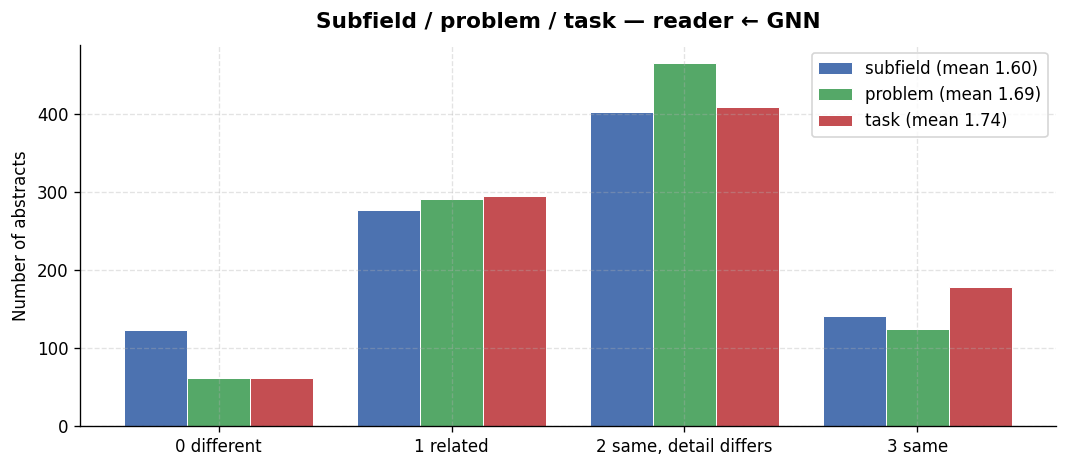

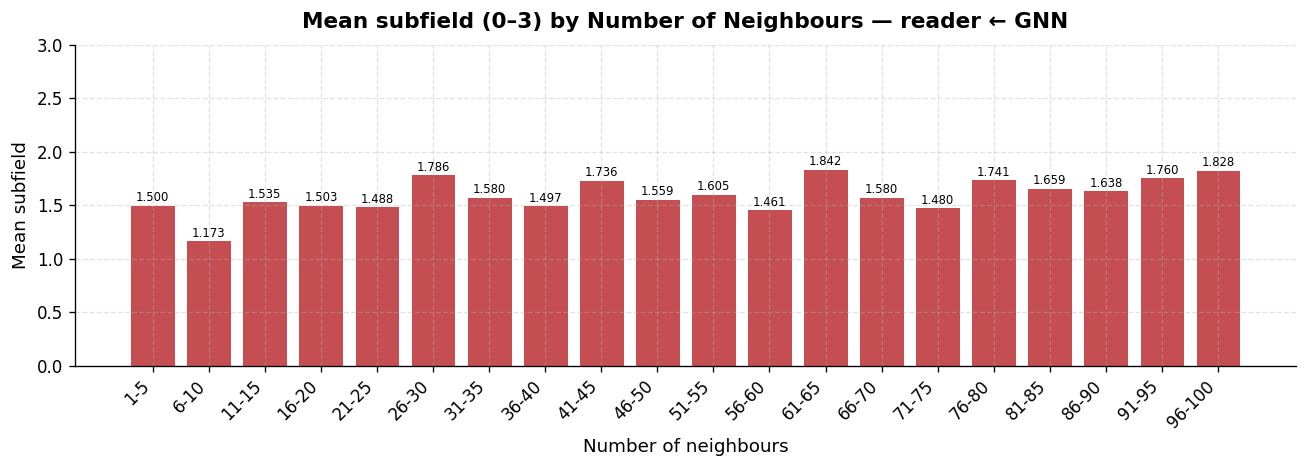

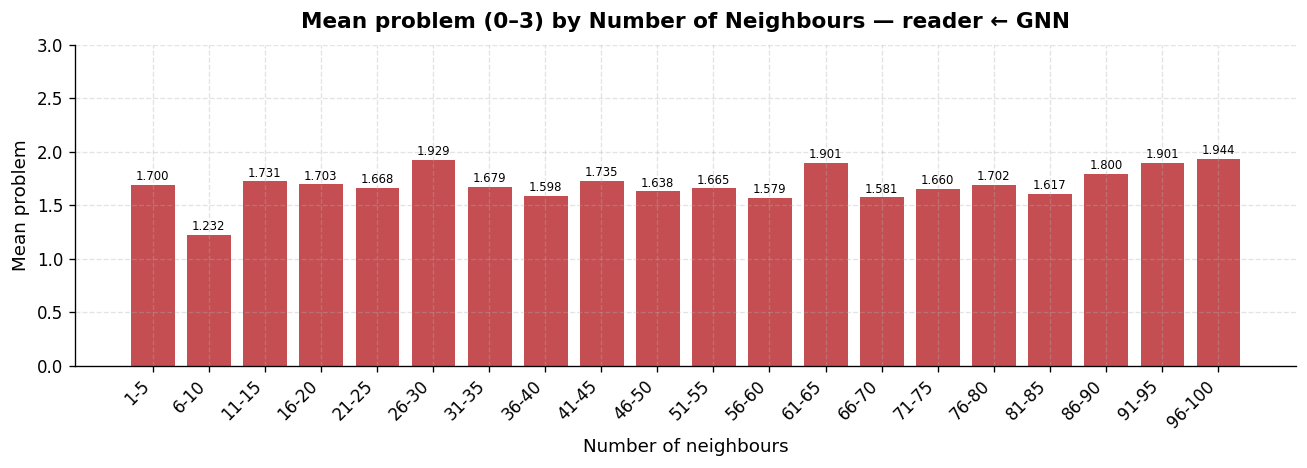

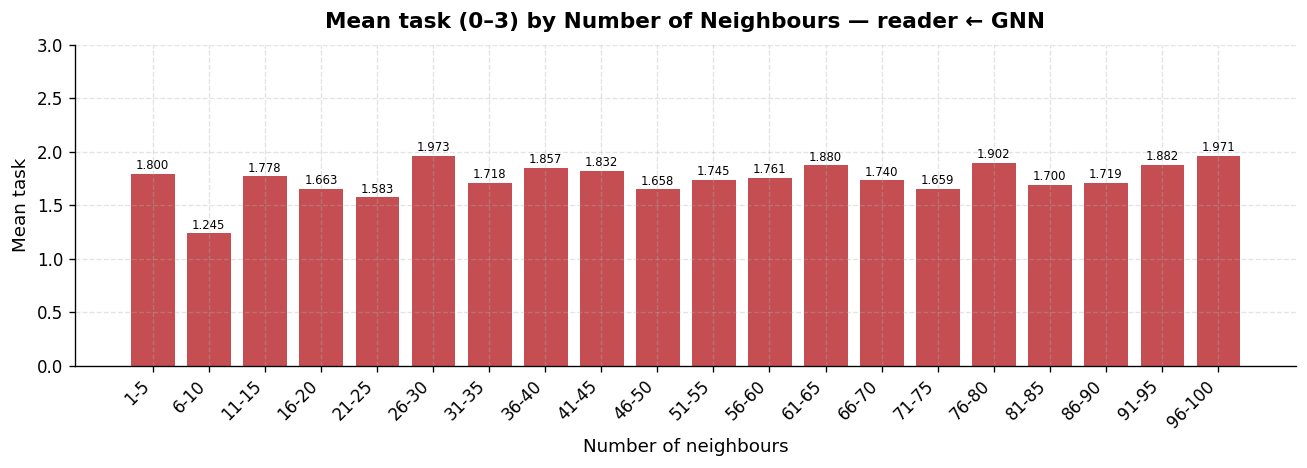

,subfield,problem,task
0,123,62,62
1,277,292,295
2,403,466,410
3,142,125,178


In [8]:
SCALE = ['subfield', 'problem', 'task']
counts = pd.DataFrame({c: df[c].dropna().round().astype(int).value_counts().reindex(range(4), fill_value=0)
                       for c in SCALE})

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for k, (c, color) in enumerate(zip(SCALE, ['#4C72B0', '#55A868', '#C44E52'])):
    ax.bar(x + (k - 1) * 0.27, counts[c].values, width=0.27, label=f'{c} (mean {df[c].mean():.2f})',
           color=color, edgecolor='white', linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(['0 different', '1 related', '2 same, detail differs', '3 same'])
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Subfield / problem / task — {ARM}', fontsize=13, fontweight='bold', pad=10)
ax.legend()
fig.tight_layout()
plt.show()

for c in SCALE:
    bar_plot(weighted_group_mean(df, c), title=f'Mean {c} (0–3) by Number of Neighbours — {ARM}',
             ylabel=f'Mean {c}', color='#C44E52', ylim=(0, 3))
counts

claims per abstract:        8.07
supported per abstract:     1.75
contradicted per abstract:  3.88
claim precision (mean):     0.218
pooled precision:           0.217
abstracts with ≥1 contradiction: 93.1%
abstracts with no claims:   0.0%


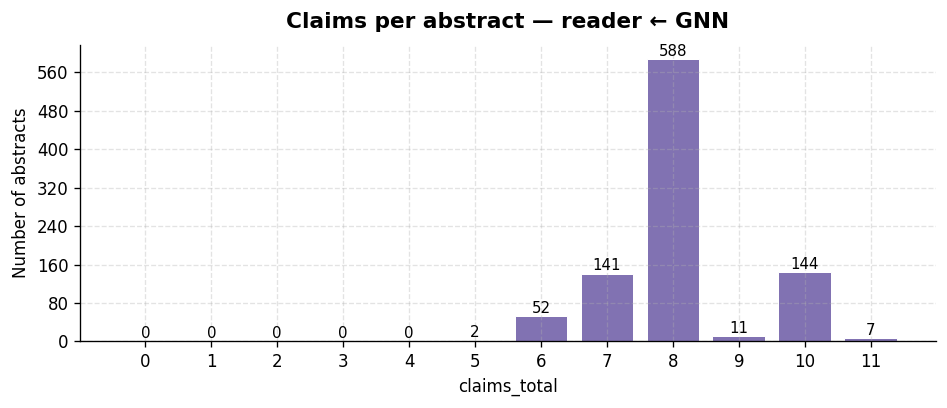

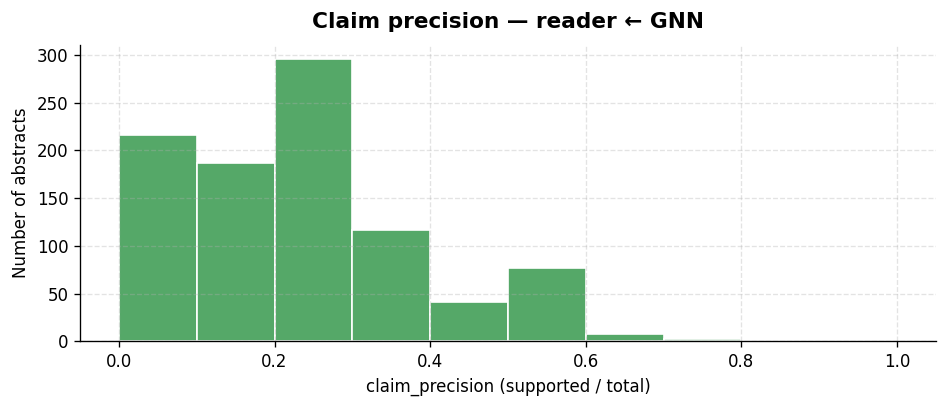

In [9]:
# ── Claims: specificity, precision, contradictions ───────────────────────────
print(f"claims per abstract:        {df['claims_total'].mean():.2f}")
print(f"supported per abstract:     {df['claims_supported'].mean():.2f}")
print(f"contradicted per abstract:  {df['claims_contradicted'].mean():.2f}")
print(f"claim precision (mean):     {df['claim_precision'].mean():.3f}")
print(f"pooled precision:           {df['claims_supported'].sum() / df['claims_total'].sum():.3f}")
print(f"abstracts with ≥1 contradiction: {(df['claims_contradicted'] > 0).mean():.1%}")
print(f"abstracts with no claims:   {(df['claims_total'] == 0).mean():.1%}")

max_claims = int(df['claims_total'].max())
dist_plot('claims_total', list(range(0, max_claims + 1)), f'Claims per abstract — {ARM}',
          'claims_total', '#8172B2')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['claim_precision'].dropna(), bins=np.linspace(0, 1, 11), color='#55A868', edgecolor='white')
ax.set_xlabel('claim_precision (supported / total)')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Claim precision — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

## C. Identification among hard distractors

The judge ranks the gold and its four nearest papers (never its own references). Chance is
20% correct and a mean rank of 3.

id correct (top-1): 41.2%   (chance 20%)
mean id rank:       2.17   (chance 3.00)
id MRR:             0.629   (chance 0.457)


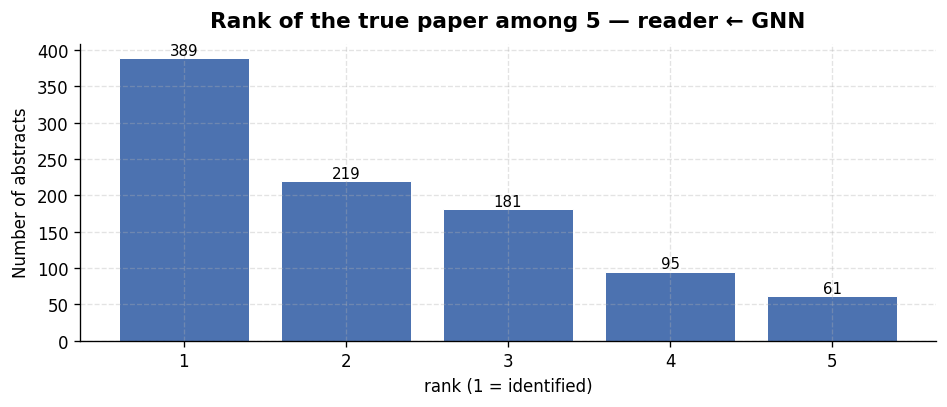

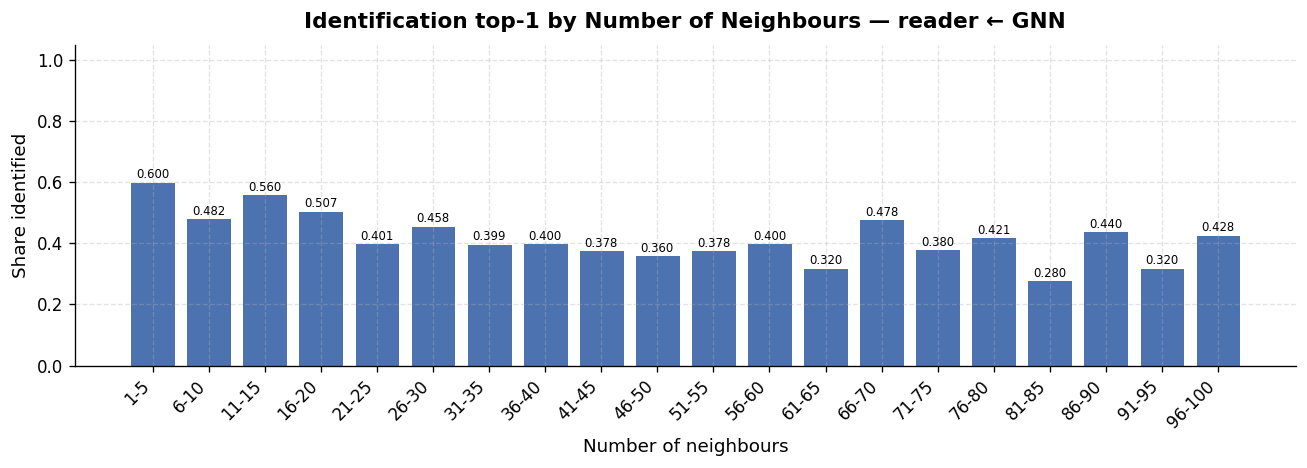

In [10]:
print(f"id correct (top-1): {df['id_correct'].mean():.1%}   (chance 20%)")
print(f"mean id rank:       {df['id_rank'].mean():.2f}   (chance 3.00)")
print(f"id MRR:             {(1 / df['id_rank']).mean():.3f}   (chance 0.457)")

counts = dist_plot('id_rank', [1, 2, 3, 4, 5], f'Rank of the true paper among 5 — {ARM}',
                   'rank (1 = identified)', '#4C72B0')
bar_plot(weighted_group_mean(df, 'id_correct'),
         title=f'Identification top-1 by Number of Neighbours — {ARM}',
         ylabel='Share identified', color='#4C72B0', ylim=(0, 1.05))

## No judge: TF-IDF identifiability and on-target margin

TF-IDF top-1 (among all 945 golds): 42.9%
TF-IDF MRR:                         0.557
on-target margin (mean):            -0.169
closer to a reference than to gold: 97.4%


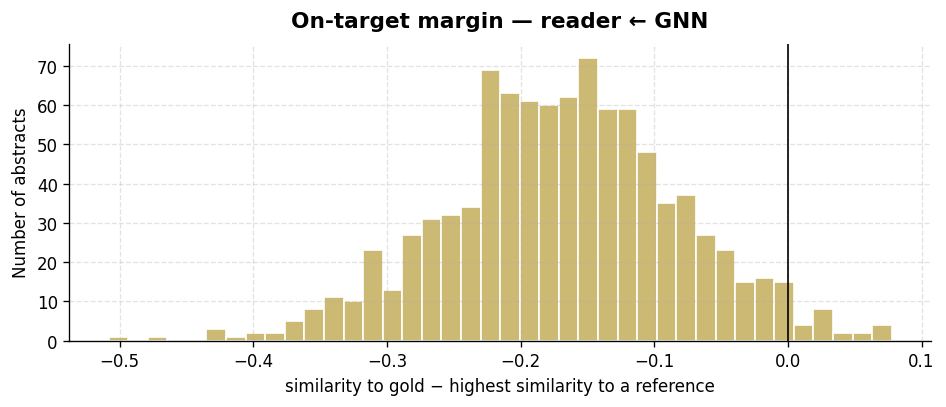

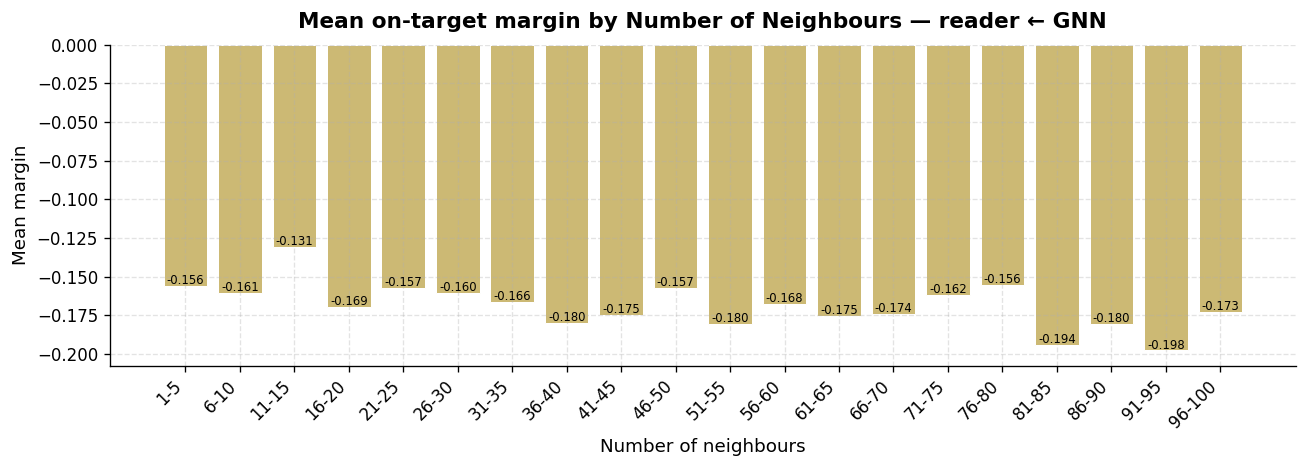

In [11]:
print(f"TF-IDF top-1 (among all {len(df)} golds): {df['tfidf_top1'].mean():.1%}")
print(f"TF-IDF MRR:                         {(1 / df['tfidf_rank']).mean():.3f}")
print(f"on-target margin (mean):            {df['ontarget_margin'].mean():.3f}")
print(f"closer to a reference than to gold: {(df['ontarget_margin'] < 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['ontarget_margin'].dropna(), bins=40, color='#CCB974', edgecolor='white')
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('similarity to gold − highest similarity to a reference')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'On-target margin — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

bar_plot(weighted_group_mean(df, 'ontarget_margin'),
         title=f'Mean on-target margin by Number of Neighbours — {ARM}',
         ylabel='Mean margin', color='#CCB974')

## D. Pairwise preference

Only present when the CSV was scored with `--against`. 1 = this arm judged better in both
orders, 0.5 = split or tie, 0 = worse in both.

In [12]:
if 'pair_score' in df.columns:
    p = df['pair_score'].dropna()
    se = p.std() / np.sqrt(len(p))
    print(f"pair score: {p.mean():.3f} ± {se:.3f} (SE)   0.5 = no preference")
    print(f"wins both orders: {(p == 1).mean():.1%}   split/tie: {(p == 0.5).mean():.1%}   "
          f"loses both: {(p == 0).mean():.1%}")
    counts = p.value_counts().reindex([0.0, 0.25, 0.5, 0.75, 1.0], fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar([str(v) for v in counts.index], counts.values, color='#937860', edgecolor='white')
    ax.set_xlabel('pair_score')
    ax.set_ylabel('Number of abstracts')
    ax.set_title(f'Pairwise preference — {ARM}', fontsize=13, fontweight='bold', pad=10)
    fig.tight_layout()
    plt.show()
    bar_plot(weighted_group_mean(df, 'pair_score'),
             title=f'Pair score by Number of Neighbours — {ARM}',
             ylabel='Mean pair score', color='#937860', ylim=(0, 1.05))
else:
    print('no pair_score column: this CSV was scored without --against')

no pair_score column: this CSV was scored without --against


## Examples

In [13]:
pd.set_option('display.max_colwidth', 2000)
SHOW = ['node_id', 'original_abstract', 'generated_abstract']

# 2 examples per task score
(df[df['task'].notna()].sort_values('task').groupby('task', sort=True)
   .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_63081/3392447683.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])


,node_id,original_abstract,generated_abstract,subfield,problem,task
0,1089,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","This paper introduces a novel optimization framework that combines adaptive learning rate methods with deep residual networks to enhance model generalization and training efficiency. Drawing on the strengths of ADADELTA and Adam, the proposed method dynamically adjusts learning rates while maintaining computational efficiency and robustness to noisy gradients. Inspired by insights from loss landscape analysis and the generalization properties of deep networks, the framework incorporates residual learning to facilitate training of deeper architectures. Empirical evaluations on benchmark datasets such as ImageNet, CIFAR-10, and COCO demonstrate improved convergence behavior, reduced generalization gap, and enhanced robustness to adversarial perturbations. Furthermore, the method is shown to produce well-calibrated uncertainty estimates through deep ensembles, offering a scalable and effective approach for training deep models in both small-batch and large-batch regimes.",0,0,0
1,15549,"Large capacity machine learning models are prone to membership inference attacks in which an adversary aims to infer whether a particular data sample is a member of the target model's training dataset. Such membership inferences can lead to serious privacy violations as machine learning models are often trained using privacy-sensitive data such as medical records and controversial user opinions. Recently, defenses against membership inference attacks are developed, in particular, based on differential privacy and adversarial regularization; unfortunately, such defenses highly impact the classification accuracy of the underlying machine learning models. In this work, we present a new defense against membership inference attacks that preserves the utility of the target machine learning models significantly better than prior defenses. Our defense, called distillation for membership privacy (DMP), leverages knowledge distillation to train machine learning models with membership privacy. We analyze the key requirements for membership privacy and provide a novel criterion to select data used for knowledge transfer, in order to improve membership privacy of the final models. DMP works effectively against the attackers with either a whitebox or blackbox access to the target model. We evaluate DMP's performance through extensive experiments on different deep neural networks and using various benchmark datasets. We show that DMP provides a significantly better tradeoff between inference resistance and classification performance than state-of-the-art membership inference defenses. For instance, a DMP-trained DenseNet provides a classification accuracy of 65.3% f

In [14]:
# Identified by TF-IDF but not by the judge, and the reverse
judge_only = df[(df['id_correct'] == 1) & (df['tfidf_rank'] > 1)]
tfidf_only = df[(df['id_correct'] == 0) & (df['tfidf_rank'] == 1)]
print(f'judge only: {len(judge_only)}   TF-IDF only: {len(tfidf_only)}')
tfidf_only.head(3)[SHOW + ['id_rank', 'id_options']]

judge only: 189   TF-IDF only: 205


,node_id,original_abstract,generated_abstract,id_rank,id_options
2,1121,"Various formal languages have been proposed in the literature for the individual-based modelling of ecological systems. These languages differ in their treatment of time and space. Each modelling language offers a distinct view and techniques for analyzing systems. Most of the languages are based on process calculi or P systems. In this article, we present a general overview of the existing modelling languages based on process calculi. We also discuss, briefly, other approaches such as P systems, cellular automata and Petri nets. Finally, we show advantages and disadvantages of these modelling languages and we propose some future research directions.","This paper introduces a novel framework for modeling and analyzing complex ecological systems by integrating spatially explicit process calculi with environmental dynamics and policy-driven event ordering. Building on formalisms such as MELA, PALPS, and Spatial CLS, the framework enables the precise description of individual-based ecological interactions, incorporating spatial attributes, movement, and environmental influences such as temperature and rainfall. A key contribution is the extension of these models with policies that define precedence relations between events, allowing for controlled exploration of system behavior under varying assumptions. The framework supports both simulation and formal verification through translation into probabilistic model checkers such as PRISM, enabling the analysis of temporal logic properties, reachability, and steady-state behavior. The approach is demonstrated through case studies involving disease transmission, predator-prey dynamics, and population dispersal, highlighting its applicability to real-world ecological and epidemiological scenarios.",2,152273|184353|213866|202507
4,1152,"In recent years, the success of deep learning has carried over from discriminative models to generative models. In particular, generative adversarial networks (GANs) have facilitated a new level of performance ranging from media manipulation to dataset re-generation. Despite the success, the potential risks of privacy breach stemming from GANs are less well explored. In this paper, we focus on membership inference attack against GANs that has the potential to reveal information about victim models' training data. Specifically, we present the first taxonomy of membership inference attacks, which encompasses not only existing attacks but also our novel ones. We also propose the first generic attack model that can be instantiated in various settings according to adversary's knowledge about the victim model. We complement our systematic analysis of attack vectors with a comprehensive experimental study, that investigates the effectiveness of these attacks w.r.t. model type, training configurations, and attack type across three diverse application scenarios ranging from images, over medical data to location data. We show consistent effectiveness in all the setups, which bridges the assumption gap and performance gap in previous study with a complete spectrum of performance across settings. We conclusively remind users to think over before publicizing any part of their models.","This paper introduces a novel framework that integrates advanced GAN training techniques, differential privacy, and progressive growing strategies to address challenges in generative modeling, privacy preservation, and model attribution. Building on improved Wasserstein GAN training, progressive growing of GANs, and differentially private GANs, our approach enhances stability, image quality, and privacy guarantees. We incorporate a privacy-protective GAN architecture with specialized modules for de-identification tasks, while also addressing information leakage risks through differential privacy and robustness against membership inference attacks. Additionally, we explore the generalization properties of GANs and pr

In [15]:
# Most contradicted abstracts
df.sort_values('claims_contradicted', ascending=False).head(3)[
    SHOW + ['claims_total', 'claims_supported', 'claims_contradicted']]

,node_id,original_abstract,generated_abstract,claims_total,claims_supported,claims_contradicted
52,8418,"Graph processing has become an important part of various areas, such as machine learning, computational sciences, medical applications, social network analysis, and many others. Various graphs, for example web or social networks, may contain up to trillions of edges. The sheer size of such datasets, combined with the irregular nature of graph processing, poses unique challenges for the runtime and the consumed power. Field Programmable Gate Arrays (FPGAs) can be an energy-efficient solution to deliver specialized hardware for graph processing. This is reflected by the recent interest in developing various graph algorithms and graph processing frameworks on FPGAs. To facilitate understanding of this emerging domain, we present the first survey and taxonomy on graph computations on FPGAs. Our survey describes and categorizes existing schemes and explains key ideas. Finally, we discuss research and engineering challenges to outline the future of graph computations on FPGAs.","This paper introduces a novel framework that combines high-level programming abstractions, efficient graph processing accelerators, and optimized execution models to enable scalable and energy-efficient graph analytics on heterogeneous platforms. Building on the Gap benchmark suite, we evaluate the performance of our framework across a diverse set of graph algorithms and input graphs. Our design integrates the edge-centric and vertex-centric processing models, as seen in X-Stream and GraphLab, with the parallel data conflict management techniques from AccuGraph and the substream-centric approach from Substream-Centric Maximum Matchings. We also incorporate hardware transactional memory and active messages to reduce synchronization overhead and improve irregular computation performance. The framework is implemented on FPGA platforms using a modular dataflow library inspired by GraphOps, enabling rapid development of accelerators with high throughput and low energy consumption. Experimental results demonstrate significant performance improvements, achieving up to 3.14x speedup over existing state-of-the-art implementations while maintaining correctness and scalability across various graph processing workloads.",10,0,10
163,31636,"Differential privacy (DP) has steadily become the de-facto standard for achieving privacy in data analysis, which is typically implemented either in the ""central"" or ""local"" model. The local model has been more popular for commercial deployments as it does not require a trusted data collector. This increased privacy, however, comes at a cost of utility and algorithmic expressibility as compared to the central model. In this work, we propose, Crypt$\epsilon$, a system and programming framework that (1) achieves the accuracy guarantees and algorithmic expressibility of the central model (2) without any trusted data collector like in the local model. Crypt$\epsilon$ achieves the ""best of both worlds"" by employing two non-colluding untrusted servers that run DP programs on encrypted data from the data owners. Although straightforward implementations of DP programs using secure computation tools can achieve the above goal theoretically, in practice they are beset with many challenges such as poor performance and tricky security proofs. To this end, Crypt$\epsilon$ allows data analysts to author logical DP programs that are automatically translated to secure protocols that work on encrypted data. These protocols ensure that the untrusted servers learn nothing more than the noisy outputs, thereby guaranteeing DP (for computationally bounded adversaries) for all Crypt$\epsilon$ programs. Crypt$\epsilon$ supports a rich class of DP programs that can be expressed via a small set of transformation and measurement operators followed by arbitrary post-processing. Further, we propose performance optimizations leveraging the fact that the o

## Paired comparison with another arm

Set `OTHER` to another arm's `evaluated_result_detailed.csv`. Differences are this arm minus
the other, per paper on the shared papers; SE = sd / √n. Positive means this arm is higher, which
is better for every metric except `claims_contradicted`, `id_rank` and `tfidf_rank`.

,reader ← GNN,reader ← refs-mean,diff,SE,n,z
metric,,,,,,
rouge1_f,0.336,0.318,0.018,0.002,945,8.746
rouge2_f,0.054,0.062,-0.008,0.001,945,-7.149
rougeL_f,0.158,0.175,-0.018,0.001,945,-15.882
bertscore_p,0.848,0.858,-0.010,0.001,945,-19.018
bertscore_r,0.843,0.831,0.012,0.000,945,36.001
bertscore_f1,0.846,0.844,0.001,0.000,945,3.887
llm_coherence,6.254,7.361,-1.107,0.061,945,-18.100
llm_language,7.596,7.893,-0.297,0.039,945,-7.584
field_match,0.789,0.773,0.015,0.013,939,1.136


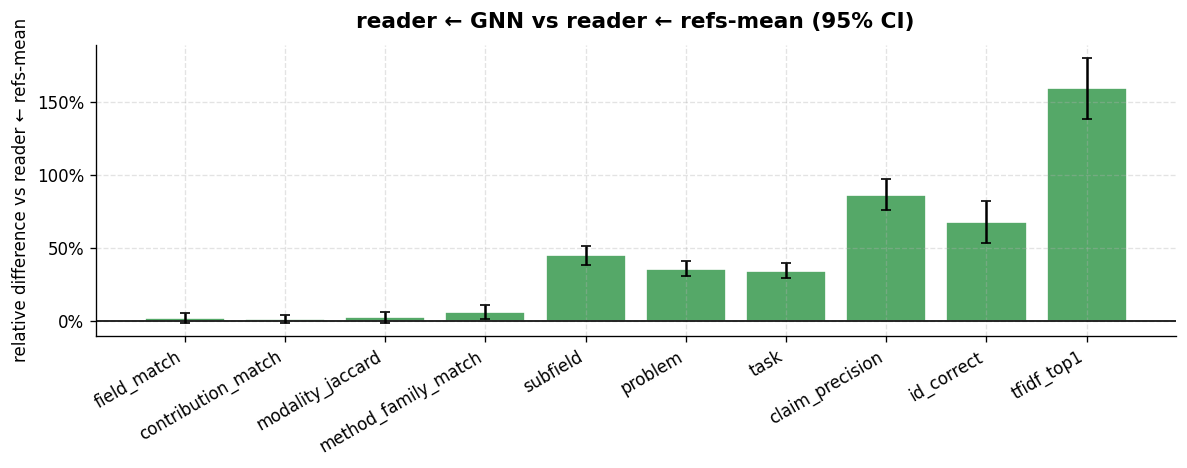

In [16]:
OTHER = '../2026-10-09-14541449_run11-reader-refs-mean/evaluated_result_detailed.csv'
OTHER_NAME = 'reader ← refs-mean'

if os.path.exists(OTHER):
    other = pd.read_csv(OTHER)
    COMPARE = [c for c in NUMERIC + ['tfidf_top1'] if c != 'pair_score']
    for col in COMPARE:
        if col in other.columns:
            other[col] = pd.to_numeric(other[col], errors='coerce')
    other['tfidf_top1'] = (other['tfidf_rank'] == 1).astype(float)
    both = df.merge(other, on='node_id', suffixes=('', '_other'))
    rows = []
    for col in COMPARE:
        d = (both[col] - both[f'{col}_other']).dropna()
        rows.append({'metric': col, ARM: both[col].mean(), OTHER_NAME: both[f'{col}_other'].mean(),
                     'diff': d.mean(), 'SE': d.std() / np.sqrt(len(d)), 'n': len(d)})
    paired = pd.DataFrame(rows).set_index('metric')
    paired['z'] = paired['diff'] / paired['SE']
    display(paired.round(3))

    # Relative difference on the main per-dimension metrics
    MAIN = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
            'subfield', 'problem', 'task', 'claim_precision', 'id_correct', 'tfidf_top1']
    rel = paired.loc[MAIN, 'diff'] / paired.loc[MAIN, OTHER_NAME]
    err = paired.loc[MAIN, 'SE'] / paired.loc[MAIN, OTHER_NAME]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(MAIN, rel.values, yerr=1.96 * err.values, capsize=3,
           color=['#55A868' if v > 0 else '#C44E52' for v in rel.values], edgecolor='white')
    ax.axhline(0, color='black', linewidth=1)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylabel(f'relative difference vs {OTHER_NAME}')
    ax.set_title(f'{ARM} vs {OTHER_NAME} (95% CI)', fontsize=13, fontweight='bold', pad=10)
    plt.xticks(rotation=30, ha='right')
    fig.tight_layout()
    plt.show()
else:
    print(f'{OTHER} not found yet')